# Motif-syntax × context swap, across annotation methods

All-by-all donor×recipient swap (`run_swap.py` → `results/swap_scores_by_method.npz`), run once **per annotation method** on a balanced 30-seq subset (10/bin). For each method the motif mask is that method's called regions.

Chimera = **recipient context** (recipient var dinuc-shuffled at its motif positions) + **donor motif syntax** (donor motif columns at donor positions). Score = mean K562 pred over 30 reps. Diagonal (donor==recipient) ≈ WT (sanity).

**Donors the method found no motif on are excluded** (empty mask = nothing to inject → the chimera is just the recipient context, identical for every such donor → stacked points). Controls per method: **motif shuffle** (motif KO) and **context shuffle** (motif alone on a dead scaffold).

In [8]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

RES = Path('results/swap_scores_by_method.npz')
FIGDIR = Path('results/figures'); FIGDIR.mkdir(parents=True, exist_ok=True)
s = np.load(RES, allow_pickle=True)
wt, bn = s['wt'], s['bins']
methods = [k[len('swap__'):] for k in s.files if k.startswith('swap__')]
SHORT = {'naive': 'naive', 'recursive_seqlets': 'recursive', 'tfmodisco_seqlets': 'tfmodisco',
         'modiscolite_seqlets': 'modiscolite', 'jaspar_fimo': 'jaspar', 'modisco_hits_mm10': 'modisco_hits'}
short = [SHORT.get(m, m) for m in methods]
ORDER = ['activating', 'neutral', 'repressive']
COL = {'activating': '#d62728', 'neutral': '#2ca02c', 'repressive': '#1f77b4'}
IDX = {b: np.where(bn == b)[0] for b in ORDER}
# donors with a real motif under each method (empty-mask donors donate nothing)
DON_OK = {m: s[f'motif_bp__{m}'] > 0 for m in methods}
def donors(m, b):
    return np.array([i for i in IDX[b] if DON_OK[m][i]], dtype=int)
print(f'{len(wt)} sequences | methods: {methods}')
print('recipients per bin:', {b: len(IDX[b]) for b in ORDER})
print('non-empty donors per method:', {m: int(DON_OK[m].sum()) for m in methods})

30 sequences | methods: ['naive', 'recursive_seqlets', 'tfmodisco_seqlets', 'modiscolite_seqlets', 'jaspar_fimo', 'modisco_hits_mm10']
recipients per bin: {'activating': 10, 'neutral': 10, 'repressive': 10}
non-empty donors per method: {'naive': 30, 'recursive_seqlets': 15, 'tfmodisco_seqlets': 30, 'modiscolite_seqlets': 30, 'jaspar_fimo': 30, 'modisco_hits_mm10': 18}


## Bin × bin mean swap, per method
Donor motif-syntax bin (rows) × recipient context bin (cols). Empty-mask donors excluded (blank cell = that method annotated no donor in the bin).

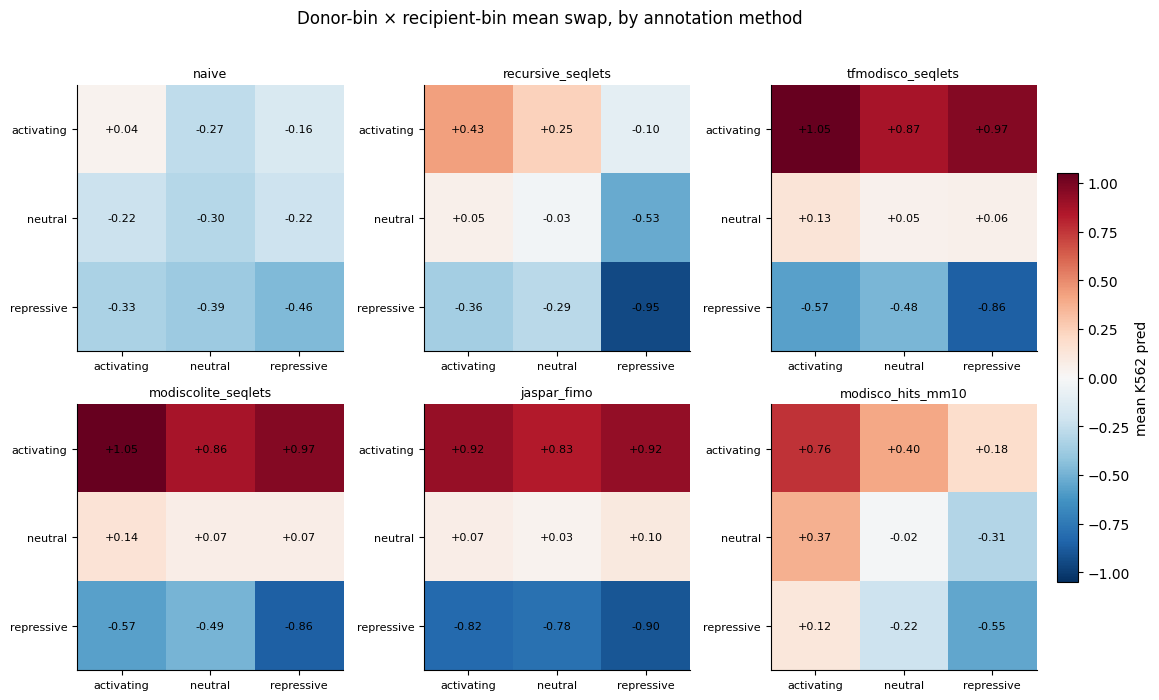

In [9]:
def binmat(m):
    sw = s[f'swap__{m}']
    return np.array([[sw[np.ix_(donors(m, db), IDX[rb])].mean() if len(donors(m, db)) else np.nan
                      for rb in ORDER] for db in ORDER])

ncol = 3
nrow = int(np.ceil(len(methods) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.8 * nrow))
axes = np.atleast_1d(axes).ravel()
vmax = np.nanmax([np.abs(binmat(m)) for m in methods])
for ax, m in zip(axes, methods):
    A = binmat(m)
    im = ax.imshow(A, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(ORDER, rotation=0, ha='center', fontsize=8)
    ax.set_yticklabels(ORDER, fontsize=8)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, '' if np.isnan(A[i, j]) else f'{A[i, j]:+.2f}',
                    ha='center', va='center', fontsize=8)
    ax.set_title(m, fontsize=9)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
for ax in axes[len(methods):]:
    ax.axis('off')
fig.colorbar(im, ax=axes.tolist(), fraction=0.02, pad=0.02, label='mean K562 pred')
fig.suptitle('Donor-bin × recipient-bin mean swap, by annotation method', fontsize=12)
fig.savefig(FIGDIR / 'binxbin_by_method.png', dpi=150, bbox_inches='tight')
plt.show()

## Donor syntax into each context, per method, with shuffle controls
WT per bin | each recipient context with one box per donor bin | **motif shuffle** (motif KO) | **context shuffle** (motif alone on dead scaffold). Empty-mask donors excluded from the swap boxes.

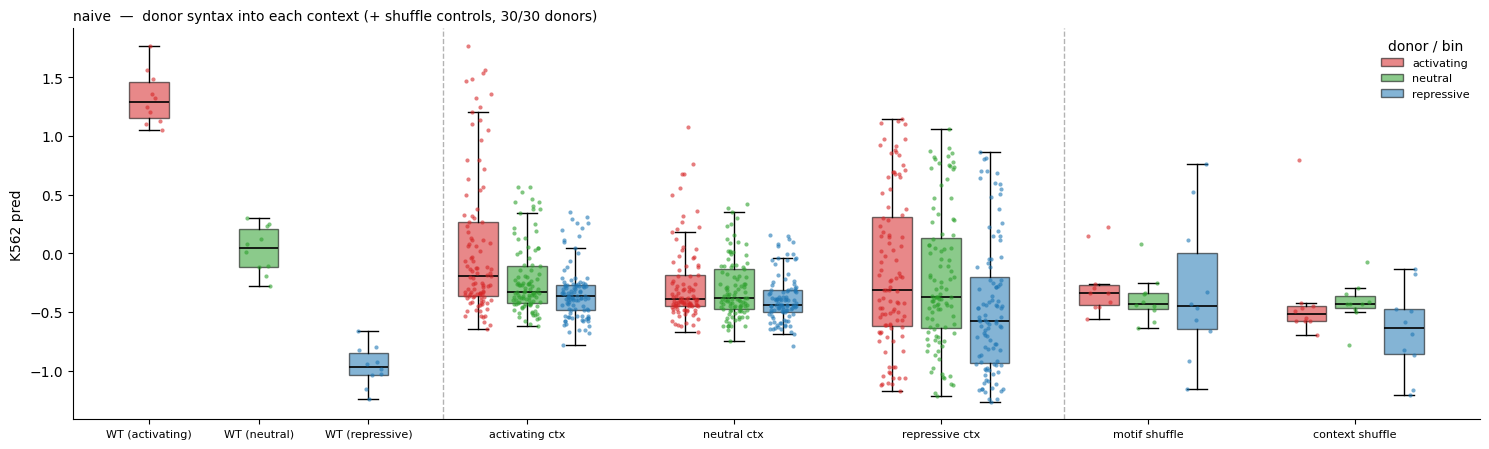

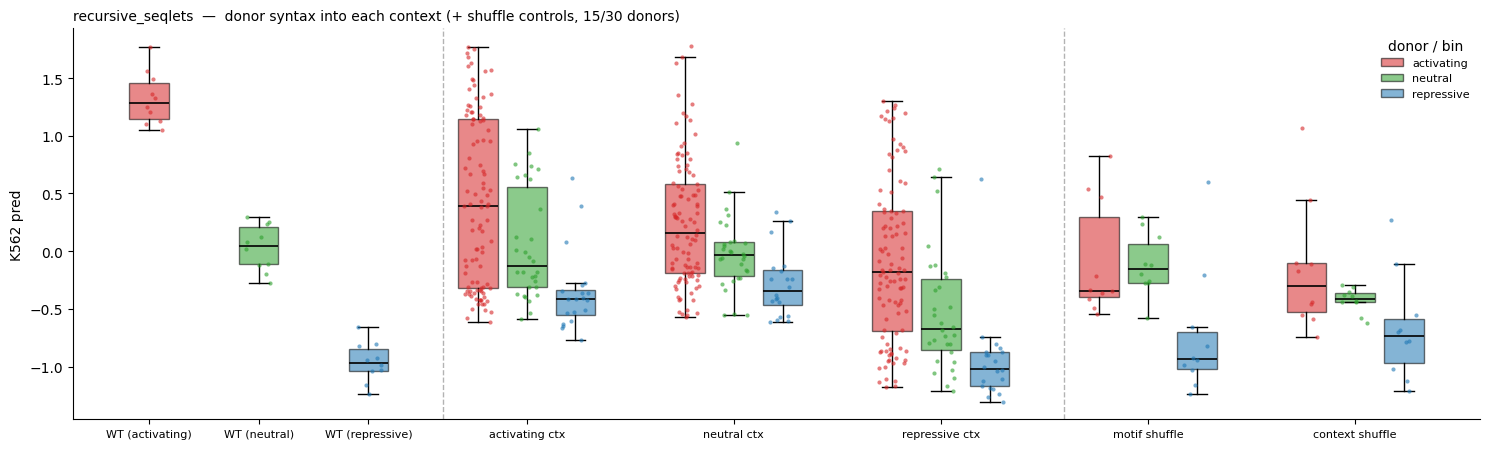

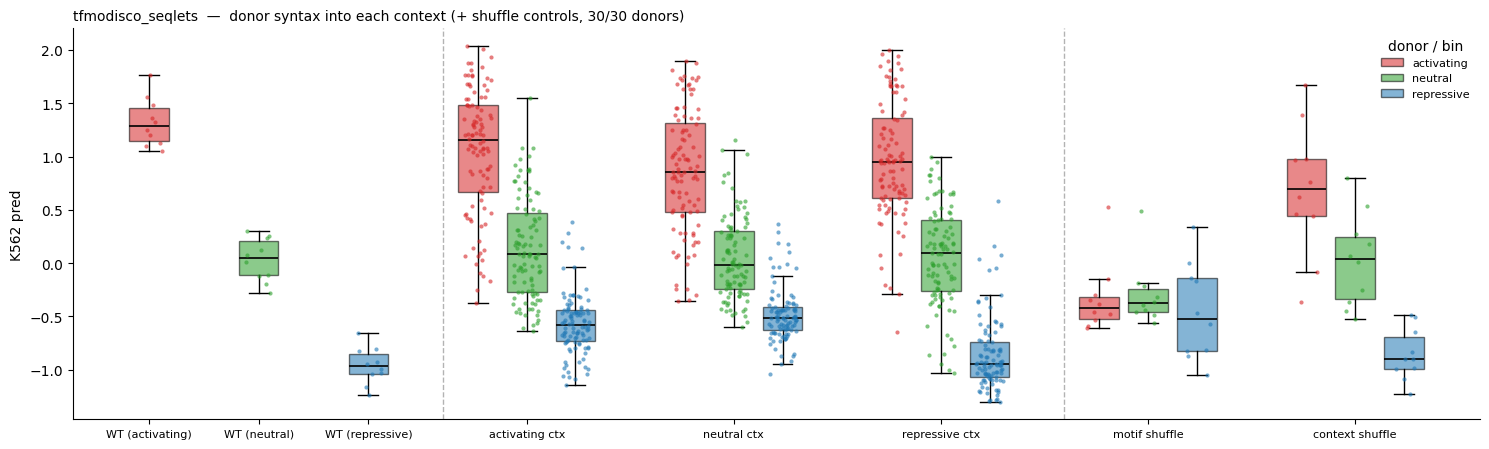

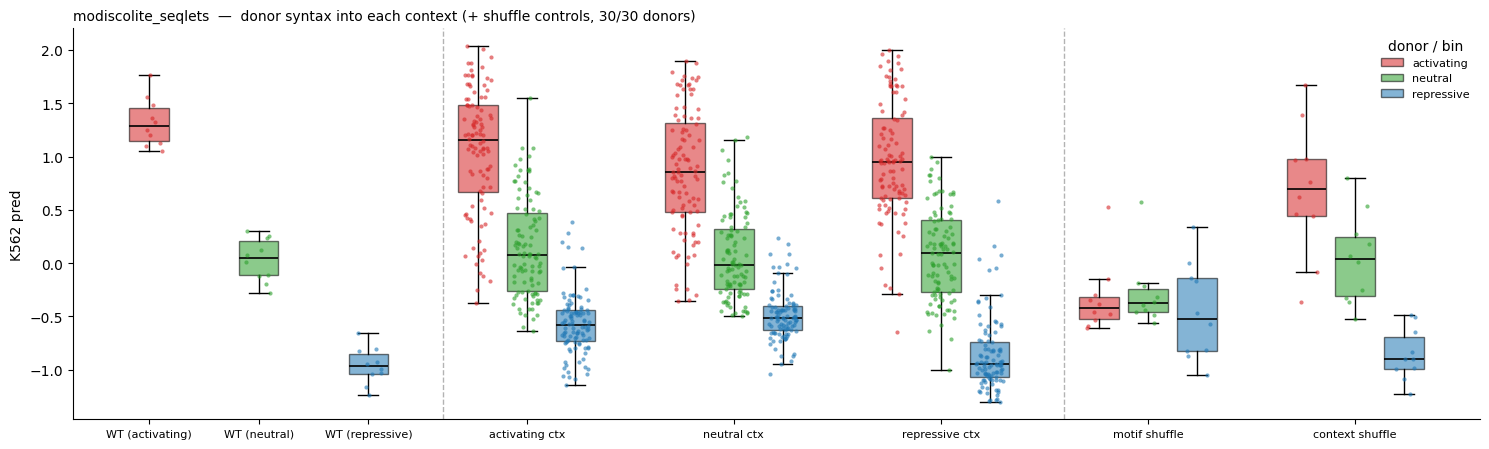

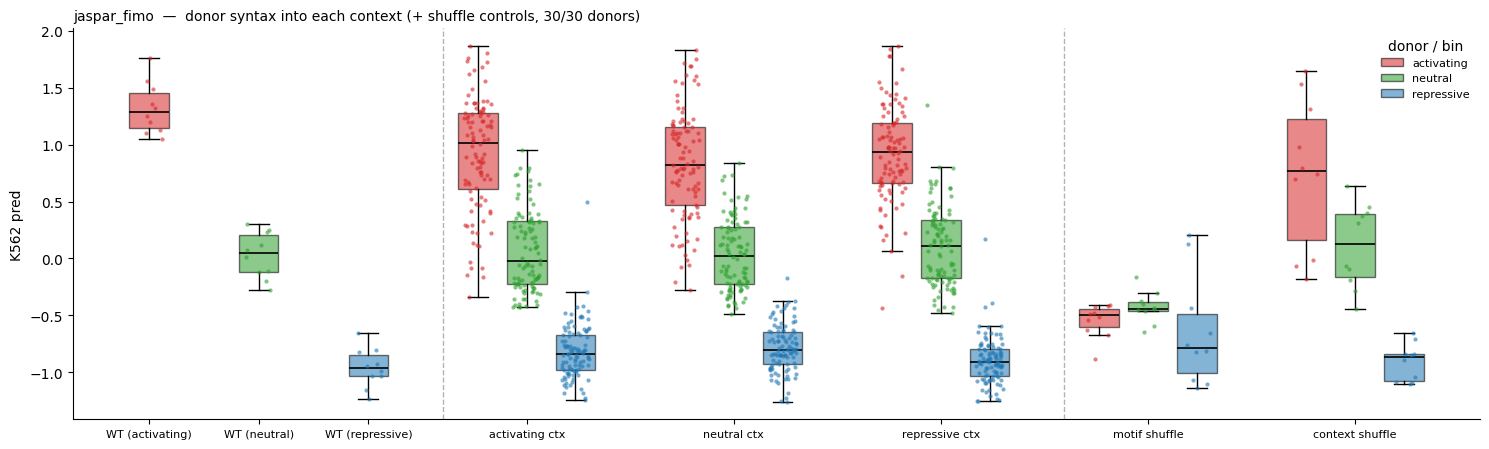

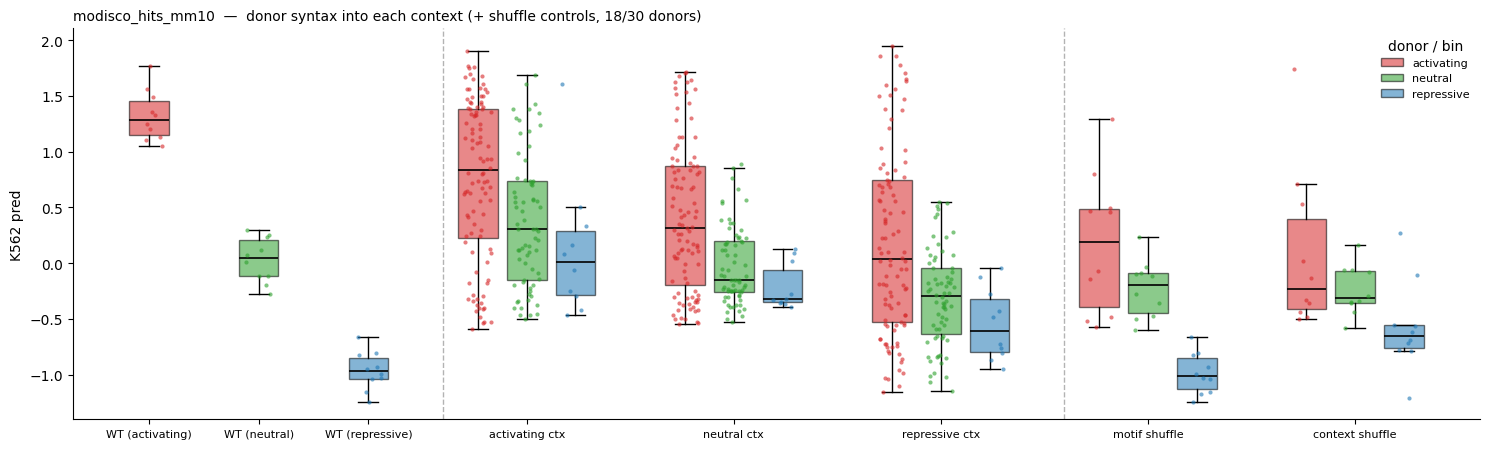

In [10]:
def swap_box(ax, m, title):
    sw = s[f'swap__{m}']
    motif_shuf, ctx_shuf = s[f'motif_shuffle__{m}'], s[f'context_shuffle__{m}']
    groups = [(f'WT ({b})', [(b, wt[IDX[b]])]) for b in ORDER]
    for rb in ORDER:
        groups.append((f'{rb} ctx', [(db, sw[np.ix_(donors(m, db), IDX[rb])].ravel()) for db in ORDER]))
    groups.append(('motif shuffle', [(b, motif_shuf[IDX[b]]) for b in ORDER]))
    groups.append(('context shuffle', [(b, ctx_shuf[IDX[b]]) for b in ORDER]))
    rng = np.random.RandomState(0)
    ticks, labels, x = [], [], 0.0
    for label, items in groups:
        start = x
        for b, v in items:
            if len(v):
                bp = ax.boxplot([v], positions=[x], widths=0.26, patch_artist=True,
                                showfliers=False, medianprops=dict(color='black', lw=1.2))
                bp['boxes'][0].set(facecolor=COL[b], alpha=0.55, edgecolor='black')
                for wk in bp['whiskers'] + bp['caps']:
                    wk.set_color('black')
                ax.scatter(x + (rng.rand(len(v)) - 0.5) * 0.18, v, s=9, color=COL[b],
                           alpha=0.6, lw=0, zorder=3)
            x += 0.32
        ticks.append((start + x - 0.32) / 2); labels.append(label); x += 0.4
    ax.axvline(ticks[len(ORDER)] - 0.55, color='0.7', lw=1, ls='--')
    ax.axvline(ticks[len(ORDER) * 2] - 0.55, color='0.7', lw=1, ls='--')
    ax.set_xticks(ticks); ax.set_xticklabels(labels, rotation=0, ha='center', fontsize=8)
    ax.set_ylabel('K562 pred'); ax.set_title(title, fontsize=10, loc='left')
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    ax.legend(handles=[Patch(facecolor=COL[b], alpha=0.55, edgecolor='black', label=b) for b in ORDER],
              frameon=False, fontsize=8, loc='upper right', title='donor / bin')

for m in methods:
    fig, ax = plt.subplots(figsize=(15, 4.6))
    swap_box(ax, m, f'{m}  —  donor syntax into each context (+ shuffle controls, {int(DON_OK[m].sum())}/30 donors)')
    plt.tight_layout()
    fig.savefig(FIGDIR / f'swapbox_{m}.png', dpi=150, bbox_inches='tight')
    plt.show()

## Correlation of the swap landscape across methods
Pearson correlation between methods of the per-pair swap scores, over a **common** set of pairs: donors non-empty in every method × all recipients, off-diagonal (self-swaps dropped since they equal WT for every method). High = the two methods' motif definitions give the same swap landscape.

13 common donors x 30 recipients -> 377 pairs


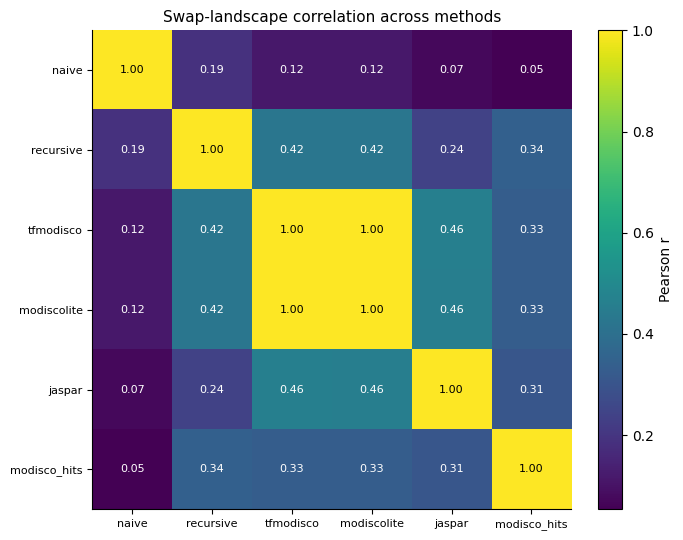

In [11]:
common = np.where(np.all([DON_OK[m] for m in methods], axis=0))[0]   # donors non-empty everywhere
dd, tt = np.meshgrid(common, np.arange(len(wt)), indexing='ij')
pm = dd != tt
flat = np.array([s[f'swap__{m}'][dd[pm], tt[pm]] for m in methods])
R = np.corrcoef(flat)
print(f'{len(common)} common donors x {len(wt)} recipients -> {int(pm.sum())} pairs')

fig, ax = plt.subplots(figsize=(7.5, 5.5))
lo = R[~np.eye(len(methods), dtype=bool)].min()
im = ax.imshow(R, cmap='viridis', vmin=lo, vmax=1)
ax.set_xticks(range(len(methods))); ax.set_yticks(range(len(methods)))
ax.set_xticklabels(short, rotation=0, ha='center', fontsize=8)
ax.set_yticklabels(short, fontsize=8)
for i in range(len(methods)):
    for j in range(len(methods)):
        ax.text(j, i, f'{R[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if R[i, j] < (lo + 1) / 2 else 'black')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Pearson r')
ax.set_title('Swap-landscape correlation across methods', fontsize=11)
plt.tight_layout()
fig.savefig(FIGDIR / 'method_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

## log2FC-from-donor versions

Same three figures, but the plotted value is **log2 fold change relative to the donor's WT** (`chimera − donor WT`; the model output is already log2 activity, so a difference is a log2FC). 0 = the recipient context reproduces the donor's native activity. The shuffle controls have no donor, so they're referenced to the recipient's own WT. Saved as `*_log2fc.png`.

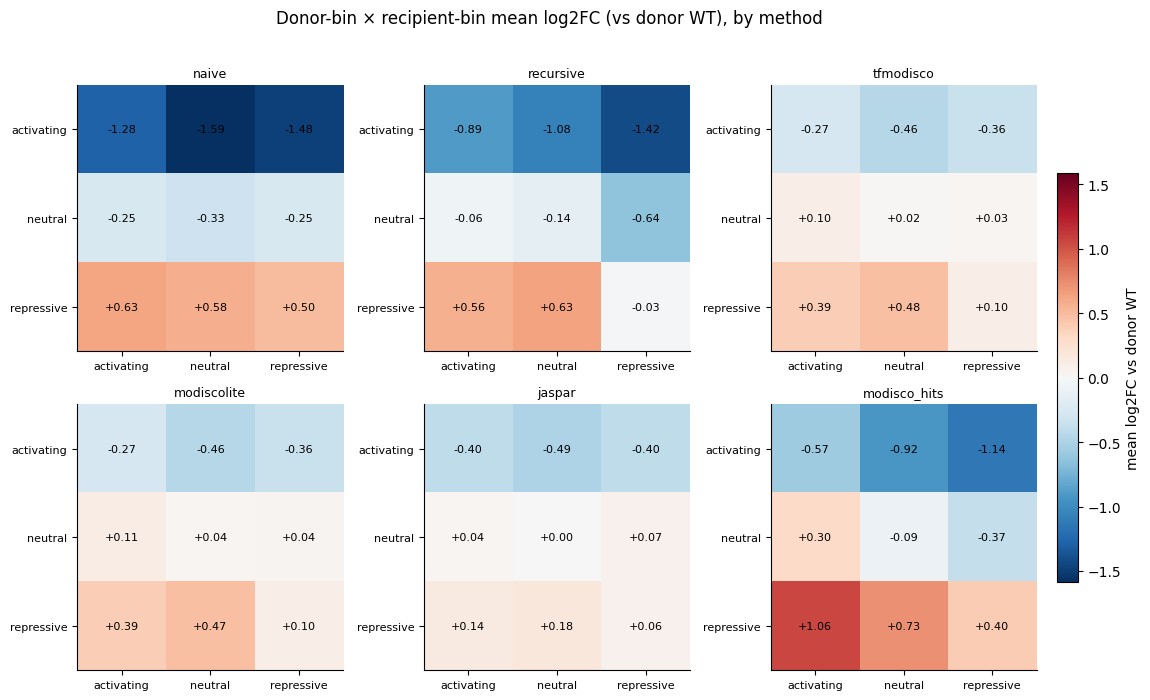

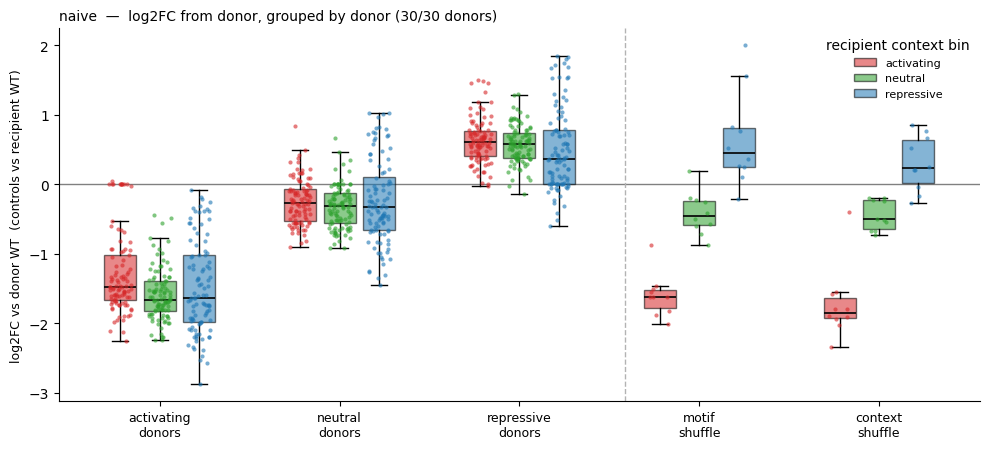

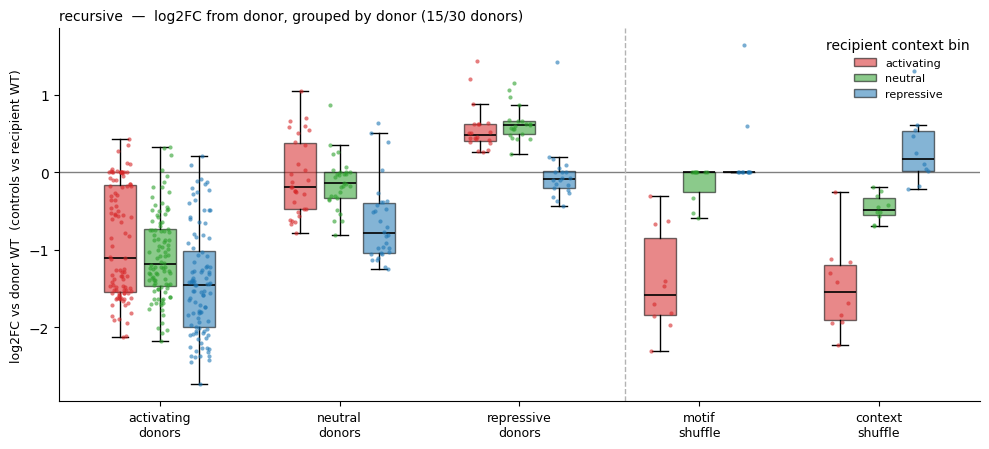

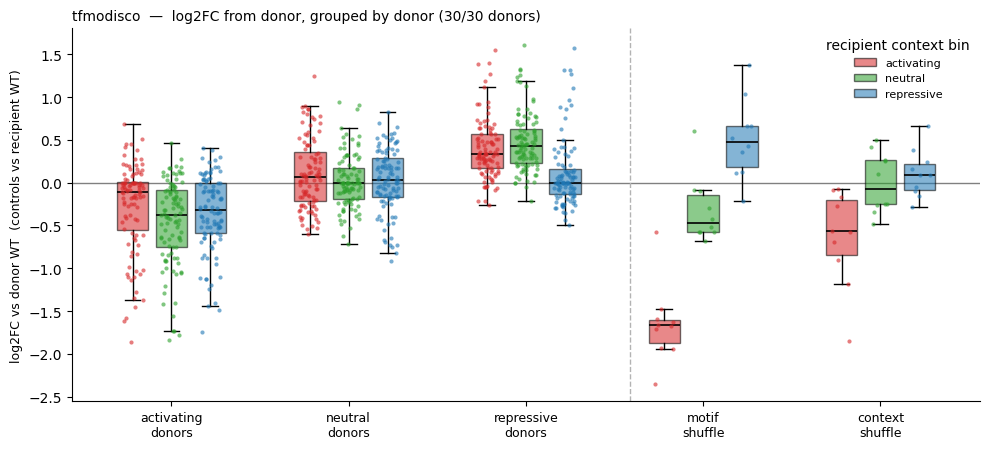

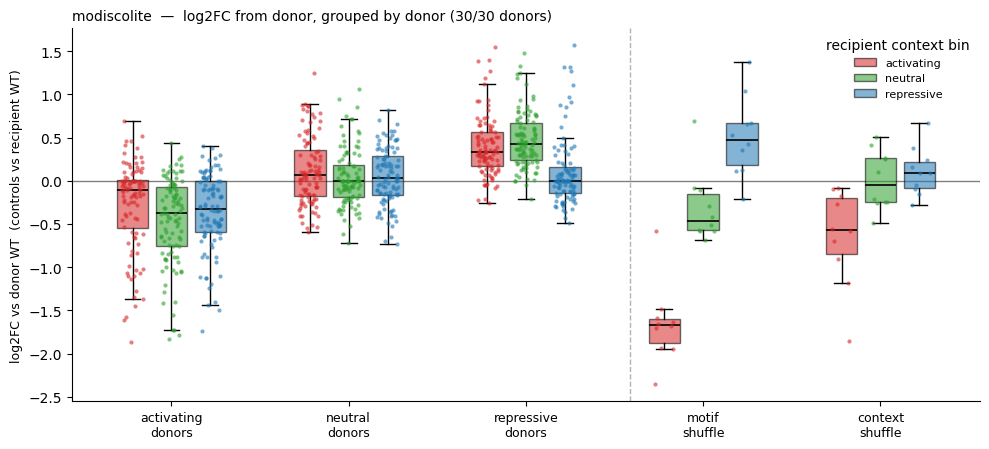

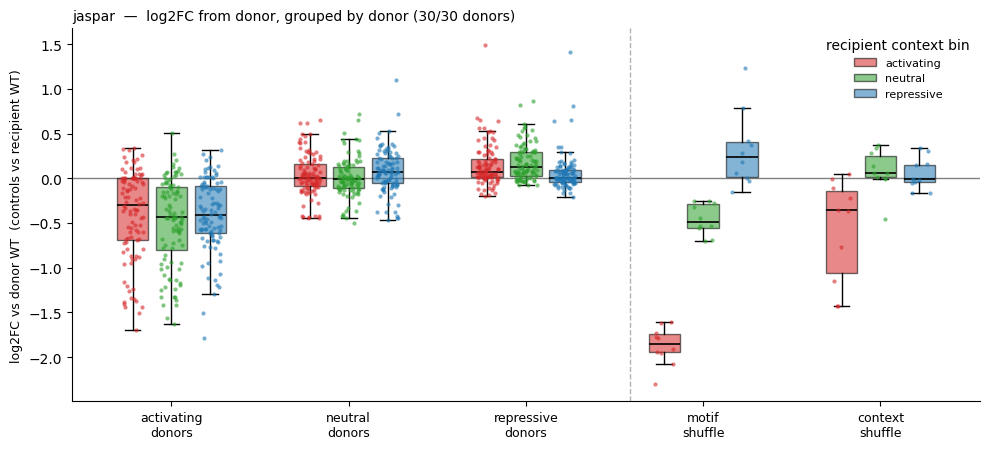

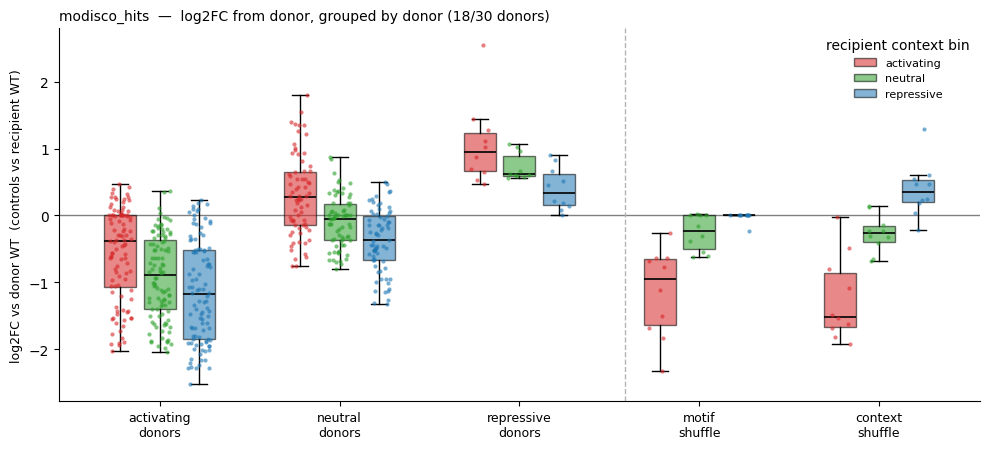

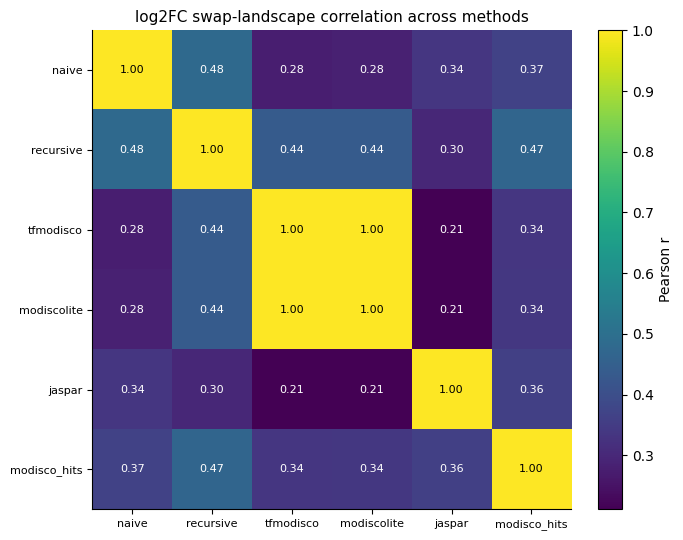

In [12]:
# log2FC from donor: model output is already log2 activity, so difference = log2 fold change.
# Swaps referenced to the DONOR's WT; shuffle controls (no donor) referenced to the RECIPIENT's WT.
# 0 = no change. Box figure is grouped by DONOR (same motif syntax) so you can read, within one
# group, how the SAME motifs behave across different recipient contexts (box color = context bin).
L2 = {m: s[f'swap__{m}'] - wt[:, None] for m in methods}   # [donor, recipient] - donor WT

# 1) bin x bin mean log2FC
def binmat_fc(m):
    L = L2[m]
    return np.array([[L[np.ix_(donors(m, db), IDX[rb])].mean() if len(donors(m, db)) else np.nan
                      for rb in ORDER] for db in ORDER])

fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.8 * nrow))
axes = np.atleast_1d(axes).ravel()
vmax = np.nanmax([np.abs(binmat_fc(m)) for m in methods])
for ax, m in zip(axes, methods):
    A = binmat_fc(m)
    im = ax.imshow(A, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(ORDER, rotation=0, ha='center', fontsize=8)
    ax.set_yticklabels(ORDER, fontsize=8)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, '' if np.isnan(A[i, j]) else f'{A[i, j]:+.2f}',
                    ha='center', va='center', fontsize=8)
    ax.set_title(SHORT.get(m, m), fontsize=9)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
for ax in axes[len(methods):]:
    ax.axis('off')
fig.colorbar(im, ax=axes.tolist(), fraction=0.02, pad=0.02, label='mean log2FC vs donor WT')
fig.suptitle('Donor-bin × recipient-bin mean log2FC (vs donor WT), by method', fontsize=12)
fig.savefig(FIGDIR / 'binxbin_log2fc.png', dpi=150, bbox_inches='tight')
plt.show()

# 2) per-method box, grouped by DONOR bin; box color = RECIPIENT context bin
def swap_box_fc(ax, m, title):
    L = L2[m]
    ms, cs = s[f'motif_shuffle__{m}'] - wt, s[f'context_shuffle__{m}'] - wt
    groups = []
    for db in ORDER:                                  # one group per donor-syntax bin
        dset = donors(m, db)
        groups.append((f'{db}\ndonors',
                       [(rb, L[np.ix_(dset, IDX[rb])].ravel() if len(dset) else np.array([]))
                        for rb in ORDER]))
    groups.append(('motif\nshuffle', [(rb, ms[IDX[rb]]) for rb in ORDER]))
    groups.append(('context\nshuffle', [(rb, cs[IDX[rb]]) for rb in ORDER]))
    rng = np.random.RandomState(0)
    ticks, labels, x = [], [], 0.0
    ax.axhline(0, color='0.5', lw=1, zorder=1)
    for label, items in groups:
        start = x
        for b, v in items:                            # b = recipient context bin (color)
            if len(v):
                bp = ax.boxplot([v], positions=[x], widths=0.26, patch_artist=True,
                                showfliers=False, medianprops=dict(color='black', lw=1.2))
                bp['boxes'][0].set(facecolor=COL[b], alpha=0.55, edgecolor='black')
                for wk in bp['whiskers'] + bp['caps']:
                    wk.set_color('black')
                ax.scatter(x + (rng.rand(len(v)) - 0.5) * 0.18, v, s=9, color=COL[b],
                           alpha=0.6, lw=0, zorder=3)
            x += 0.32
        ticks.append((start + x - 0.32) / 2); labels.append(label); x += 0.5
    ax.axvline(ticks[len(ORDER)] - 0.6, color='0.7', lw=1, ls='--')   # donor groups | controls
    ax.set_xticks(ticks); ax.set_xticklabels(labels, rotation=0, ha='center', fontsize=9)
    ax.set_ylabel('log2FC vs donor WT  (controls vs recipient WT)', fontsize=9)
    ax.set_title(title, fontsize=10, loc='left')
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    ax.legend(handles=[Patch(facecolor=COL[b], alpha=0.55, edgecolor='black', label=b) for b in ORDER],
              frameon=False, fontsize=8, loc='upper right', title='recipient context bin')

for m in methods:
    fig, ax = plt.subplots(figsize=(10, 4.6))
    swap_box_fc(ax, m, f'{SHORT.get(m, m)}  —  log2FC from donor, grouped by donor ({int(DON_OK[m].sum())}/30 donors)')
    plt.tight_layout()
    fig.savefig(FIGDIR / f'swapbox_log2fc_{m}.png', dpi=150, bbox_inches='tight')
    plt.show()

# 3) correlation of the log2FC landscape (same common pairs as above)
flatL = np.array([L2[m][dd[pm], tt[pm]] for m in methods])
RL = np.corrcoef(flatL)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
loL = RL[~np.eye(len(methods), dtype=bool)].min()
im = ax.imshow(RL, cmap='viridis', vmin=loL, vmax=1)
ax.set_xticks(range(len(methods))); ax.set_yticks(range(len(methods)))
ax.set_xticklabels(short, rotation=0, ha='center', fontsize=8)
ax.set_yticklabels(short, fontsize=8)
for i in range(len(methods)):
    for j in range(len(methods)):
        ax.text(j, i, f'{RL[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if RL[i, j] < (loL + 1) / 2 else 'black')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Pearson r')
ax.set_title('log2FC swap-landscape correlation across methods', fontsize=11)
plt.tight_layout()
fig.savefig(FIGDIR / 'method_correlation_log2fc.png', dpi=150, bbox_inches='tight')
plt.show()